# Minimal PMU Feature Sets for Real-Time Power Grid Attack Detection

**Giovanni Di Domenico**

## Research question

> What is the minimal set of PMU-derived features needed to reliably detect cyber-physical
> attacks on a power grid in real time, and does a model trained on that reduced feature set
> generalize across relays it wasn't trained on?

This joins two things that prior published work on this dataset has not done together:

1. **Minimal feature subset framed as an embedded-deployment question.** Published work has
   identified impedance and phase angle as top features, but has not asked what the *smallest*
   feature set is that a single relay could compute on-line at 120 Hz.
2. **Leave-one-relay-out generalization.** Instead of a random train/test split, train on three
   relays and test on the fourth, repeated four ways. This allows us to test whether the model learns a general
   attack signature or memorizes relay-specific patterns.

The result that matters is the interaction: **does the minimal feature set generalize to an
unseen relay as well as the full feature set does?**

## 1. Data provenance and reproducibility

**Source.** Mississippi State University / Oak Ridge National Laboratory *Power System Attack
Dataset* - https://www.kaggle.com/datasets/bachirbarika/power-system/data

**System modeled.** A 3-bus / 2-line power transmission system with four protective relays
(R1–R4). Each relay contains a Phasor Measurement Unit (PMU) sampling at **120 Hz**.

**Files.** Originally distributed as 15 CSVs of  ~5,000 rows each
(`binaryAllNaturalPlusNormalVsAttacks/data1.csv` … `data15.csv`). I concatenated these with a
`source_file` provenance column into `power_system_combined.csv` — **78,377 rows × 130 columns**
(128 features + `marker` label + `source_file`).

**Label.** `marker` ∈ {`Attack`, `Natural`}, 55,663 / 22,714 — a 71.0 / 29.0 split. The majority-class
baseline is therefore **0.710 accuracy**. The selected headline metric was F1 over recall because optimizing for recall would produce near-100% results, considering the 71/29 class imbalance. 

## 2. Load and integrity checks

In [1]:
#Set up imports, chart theme, paths
#assumes power_system_combined.csv in the directory
from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from sklearn.inspection import permutation_importance
import xgboost as xgb
import shap

RANDOM_STATE = 42
DATA_PATH = Path("power_system_combined.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

#Chart colors and theme
C = {
    "s1": "#2a78d6",   # blue
    "s2": "#eb6834",   # orange
    "s3": "#1baf7a",   # aqua
    "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
    "grid": "#e1e0d9", "axis": "#c3c2b7", "surface": "#fcfcfb",
}
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

mpl.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"],
    "savefig.facecolor": C["surface"], "savefig.dpi": 200, "figure.dpi": 110,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": C["ink"], "axes.labelcolor": C["ink2"],
    "xtick.color": C["muted"], "ytick.color": C["muted"],
    "axes.edgecolor": C["axis"], "axes.linewidth": 1.0,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
    "axes.titlesize": 12, "axes.titlelocation": "left",
})


def savefig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    return path


print("pandas", pd.__version__, "| numpy", np.__version__,
      "| xgboost", xgb.__version__, "| shap", shap.__version__)

pandas 3.0.1 | numpy 2.2.6 | xgboost 3.1.3 | shap 0.50.0


In [2]:
#Basic data checks/analysis
df = pd.read_csv(DATA_PATH)

assert df.shape == (78377, 130), f"unexpected shape {df.shape}"
assert df.isna().sum().sum() == 0, "unexpected missing values"

counts = df["marker"].value_counts()
assert counts["Attack"] == 55663 and counts["Natural"] == 22714
assert df["source_file"].nunique() == 15, "not all 15 source files present"

BASE_RATE = counts.max() / len(df)
print(f"shape          : {df.shape}")
print(f"class balance  : {counts.to_dict()}")
print(f"majority base  : {BASE_RATE:.4f}   <- any model at or below this is worthless")
print(f"source files   : {df['source_file'].nunique()} (all 15 present, incl. data7.csv)")

shape          : (78377, 130)
class balance  : {'Attack': 55663, 'Natural': 22714}
majority base  : 0.7102   <- any model at or below this is worthless
source files   : 15 (all 15 present, incl. data7.csv)


## **Data Integrity Check**

In [3]:
floats = df.select_dtypes(include="float64").shape[1]
ints = df.select_dtypes(include="int64").shape[1]
strings = df.select_dtypes(include="object").shape[1]

print("Number of float64 columns:", floats)
print("Number of int64 columns:", ints)
print("Number of object columns:", strings)

print(f"Total columns: {floats + ints + strings}")

print(f"Number of duplicate rows: {df.duplicated().sum()}")

print("\n", df["source_file"].value_counts().sort_index().to_string())



Number of float64 columns: 113
Number of int64 columns: 15
Number of object columns: 2
Total columns: 130


C:\Users\gmdid\AppData\Local\Temp\ipykernel_23544\3940743069.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  strings = df.select_dtypes(include="object").shape[1]


Number of duplicate rows: 8

 source_file
data1.csv     4966
data10.csv    5569
data11.csv    5251
data12.csv    5224
data13.csv    5271
data14.csv    5115
data15.csv    5276
data2.csv     5069
data3.csv     5415
data4.csv     5202
data5.csv     5161
data6.csv     4967
data7.csv     5236
data8.csv     5315
data9.csv     5340


**Data Integrity Reflection:**
Low number of duplicate rows overall (8 is negligible in a dataset of ~78K that are highly autocorrelated), 113 total float cols, 15 int cols, and 2 string cols.

## 3. Column decode

Understanding what each of the columns mean for feature importance interpretability

| Token | Meaning |
|---|---|
| `R1`–`R4` | Which relay the measurement comes from |
| `PA` | **P**hasor **A**ngle (degrees) |
| `PM` | **P**hasor **M**agnitude |
| `:V` / `:VH` | Voltage magnitude / voltage angle |
| `:I` / `:IH` | Current magnitude / current angle |
| `R#:F` | Frequency (Hz, nominal 60) |
| `R#:DF` | Rate of change of frequency (df/dt) |
| `R#-PA:Z` | **Apparent impedance magnitude** (Z = V / I) -> Ohm's Law |
| `R#-PA:ZH` | Apparent impedance angle |
| `R#:S` | Relay status word (bitfield — *not* a PMU measurement) |

### The 12 phasor pairs per relay

Each relay reports 12 phasor pairs, in a fixed order that follows standard power-engineering
fault analysis:

| Pairs | Quantity |
|---|---|
| 1–3 | Three-phase **voltage** (A, B, C) |
| 4–6 | Three-phase **current** (A, B, C) |
| 7–9 | **Symmetrical-component voltage** (positive, negative, zero sequence) |
| 10–12 | **Symmetrical-component current** (positive, negative, zero sequence) |

The symmetrical-component decomposition is the classical tool for distinguishing balanced from
unbalanced faults: a healthy three-phase system has near-zero negative- and zero-sequence
components, so non-zero values there indicate an asymmetric disturbance.

### `R#-PA:Z` is a critical column

Distance (impedance) protective relays trip on **apparent impedance**. Under normal load the
line looks like a large impedance; during a fault, current spikes and Z collapses toward the
origin of the R–X plane, crossing the relay's trip characteristic. A false-data-injection attack
that wants to cause a spurious trip must therefore spoof exactly this signal. Prior published
work on this dataset independently ranks impedance and phase angle as the most diagnostic
features, so `PA:Z` is both the physically motivated and the empirically expected winner.

### The cyber-layer log columns

`control_panel_log1-4`, `relay1_log`–`relay4_log`, `snort_log1-4` - 12 columns from the control
panel, relay logs, and the Snort intrusion-detection system. These are network/cyber-layer, not
PMU-derived. Section 6 tests empirically whether they carry any signal.

In [4]:
RELAYS = [1, 2, 3, 4]

GENERIC_PHASOR = []
for i in range(1, 13):
    kind = "V" if (i <= 3 or 7 <= i <= 9) else "I"
    GENERIC_PHASOR += [f"PA{i}:{kind}H", f"PM{i}:{kind}"]

GENERIC_29 = GENERIC_PHASOR + ["F", "DF", "PA:Z", "PA:ZH", "S"]
GENERIC_PMU_28 = [g for g in GENERIC_29 if g != "S"]


def wide(relay: int, generic: str) -> str:
    #Map a relay number + generic feature name onto its wide column name.
    return f"R{relay}:{generic}" if generic in ("F", "DF", "S") else f"R{relay}-{generic}"


PMU_COLS = [wide(r, g) for r in RELAYS for g in GENERIC_PMU_28]
STATUS_COLS = [wide(r, "S") for r in RELAYS]
Z_COLS = [wide(r, "PA:Z") for r in RELAYS]
LOG_COLS = ([f"control_panel_log{i}" for i in RELAYS]
            + [f"relay{i}_log" for i in RELAYS]
            + [f"snort_log{i}" for i in RELAYS])

missing = [c for c in PMU_COLS + STATUS_COLS + LOG_COLS if c not in df.columns]
assert not missing, f"column-name mismatch: {missing[:5]}"
assert len(GENERIC_PMU_28) == 28 and len(PMU_COLS) == 112
assert len(PMU_COLS) + len(STATUS_COLS) + len(LOG_COLS) + 2 == 130, "columns unaccounted for"

print(f"{len(GENERIC_PMU_28)} PMU features per relay -> {len(PMU_COLS)} wide columns")
print(f"{len(STATUS_COLS)} status words | {len(LOG_COLS)} cyber logs | + marker, source_file = 130")

28 PMU features per relay -> 112 wide columns
4 status words | 12 cyber logs | + marker, source_file = 130


## 4. The infinity investigation

The four `R#-PA:Z` columns contain infinities. Since Z = V / I, an infinity means the measured
current was zero. The question this section answers is **what physical state that corresponds
to**, because the answer determines whether these values are corruption to be discarded or
signal to be preserved.

In [5]:
z_inf = np.isposinf(df[Z_COLS])

print("Infinity census:")
for c in Z_COLS:
    print(f"  {c:10s}  +inf={int(np.isposinf(df[c]).sum()):6d}"
          f"   -inf={int(np.isneginf(df[c]).sum()):4d}   nan={int(df[c].isna().sum()):4d}")
print(f"\ntotal inf cells      : {int(z_inf.sum().sum())}")
print(f"rows with >=1 inf    : {int(z_inf.any(axis=1).sum())}")

#check if infinities are confined to Z columns (the angle columns and everything else should be clean)
num_cols = [c for c in df.columns
            if c not in Z_COLS and pd.api.types.is_numeric_dtype(df[c])]
assert not np.isinf(df[num_cols].to_numpy()).any(), "infinities found outside the Z columns"
print("confirmed: infinities occur only in the four R#-PA:Z columns, and only as +inf")

Infinity census:
  R1-PA:Z     +inf=  2877   -inf=   0   nan=   0
  R2-PA:Z     +inf=  2607   -inf=   0   nan=   0
  R3-PA:Z     +inf=  2633   -inf=   0   nan=   0
  R4-PA:Z     +inf=  2789   -inf=   0   nan=   0

total inf cells      : 10906
rows with >=1 inf    : 6304
confirmed: infinities occur only in the four R#-PA:Z columns, and only as +inf


In [6]:
#Check other metrics at the infinite-impedance rows. 
r = 1
inf_r = np.isposinf(df[wide(r, "PA:Z")])
probe = ([wide(r, f"PM{i}:I") for i in (4, 5, 6, 10)]
         + [wide(r, "PM1:V"), wide(r, "F"), wide(r, "PA1:VH")])

evidence = pd.DataFrame({
    "median @ Z=inf": [df.loc[inf_r, c].median() for c in probe],
    "max @ Z=inf": [df.loc[inf_r, c].max() for c in probe],
    "frac nonzero @ Z=inf": [float((df.loc[inf_r, c] != 0).mean()) for c in probe],
    "median @ Z finite": [df.loc[~inf_r, c].median() for c in probe],
}, index=probe).round(4)

print(f"R{r}: {int(inf_r.sum())} rows with infinite impedance\n")
display(evidence)

R1: 2877 rows with infinite impedance



,median @ Z=inf,max @ Z=inf,frac nonzero @ Z=inf,median @ Z finite
R1-PM4:I,0.0000,0.0000,0.0000,384.1648
R1-PM5:I,0.0000,0.0000,0.0000,388.5594
R1-PM6:I,0.0000,0.0000,0.0000,381.9675
R1-PM10:I,0.0000,0.0000,0.0000,385.4466
R1-PM1:V,134292.4341,147305.4613,0.9701,131659.7408
R1:F,60.0200,60.5490,0.9972,60.0000
R1-PA1:VH,-18.9019,179.8686,0.9701,-29.1893


In [7]:
# Corroboration from the relay status word, and the class balance of the event.
print("R1:S at Z=inf rows (top 4):")
print(df.loc[inf_r, wide(r, "S")].value_counts().head(4).to_string())
print("\nR1:S overall (top 4):")
print(df[wide(r, "S")].value_counts().head(4).to_string())

print("\nInfinite-impedance rate by class:")
rate = pd.crosstab(df["marker"], z_inf.any(axis=1), normalize="index")
rate.columns = ["finite Z", "has inf Z"]
print(rate.round(4).to_string())

R1:S at Z=inf rows (top 4):
R1:S
2048      1373
0         1184
2058       307
272384       6

R1:S overall (top 4):
R1:S
0         75975
2048       1565
2058        570
270336      199

Infinite-impedance rate by class:
         finite Z  has inf Z
marker                      
Attack     0.9242     0.0758
Natural    0.9082     0.0918


### **`inf` Handling Aspects of the data above going into the decision**
- Currents at infinite-Z rows are exactly zero, not even small values (0.0003). This is demonstrated through the `max` column, which shows that the absolute maximum for current (I) is 0.0000. 
- To the same vein, voltage and frequency are nominal values in those same rows, showing that electricity is ready to be pushed, yet it's not being released - like a water hose that's turned on to max flow but taped shut at the end. In terms of the project, this means that the breaker has opened (tripped), stopping the flow. 
- `inf` rate between Attack and Natural classes is fairly even, meaning that a model can't solely check if an inf is present to make a bias toward one class. A flag wouldn't be a dead giveaway, which is why we can use it. 
- **Handling Decision**: `<col>__open` binary flag shows us the aftermath of a breaker trip - the relay's line being de-energized. `inf` Z values will be capped at a high quantile to keep Z usable for models that can't take `inf` as an input. 
-  The cap should only be fit on the **training data** to not introduce data leakage. The specific cap value could change results for the logistic regression because it bases its predictions off the numeric distance between values, while tree based models that use threshold splits and rank-based logic aren't as susceptible. 

In [8]:
#Group contiguous runs of the same label into blocks. 
#A block is a contiguous run of rows with the same label and source file. 
#The block_id is a unique identifier for each block.
#This is a necessary step, as the data is strongly autocorrelated, 
#and a random split would put near-duplicate rows in both train and test sets, 
#inflating performance metrics.
change = ((df["marker"] != df["marker"].shift())
          | (df["source_file"] != df["source_file"].shift()))
df["block_id"] = change.cumsum()

blocks = df.groupby("block_id").agg(rows=("marker", "size"),
                                    label=("marker", "first"),
                                    n_labels=("marker", "nunique"),
                                    src=("source_file", "first"))

assert df["block_id"].nunique() == 75, f"expected 75 blocks, got {df['block_id'].nunique()}"
assert (blocks["n_labels"] == 1).all(), "a block spans more than one label"
assert (blocks.groupby("src").size() == 5).all(), "every source file should hold exactly 5 blocks"

adj = (df["marker"].values[1:] == df["marker"].values[:-1]).mean()
print(f"{len(blocks)} contiguous label-pure blocks  (15 files x 5 runs)")
print(f"rows per block: min={blocks.rows.min()}  median={int(blocks.rows.median())}  max={blocks.rows.max()}")
print(f"adjacent rows sharing a label: {adj:.4f}")

# Every file has the SAME N/A/N/A/N layout, so a "block" is not one event. It is
# ~100+ events of one class concatenated. Split blocks at large discontinuities to
# recover an approximate per-event grouping.
v = df["R1-PM1:V"].to_numpy()
jump = np.r_[True, np.abs(np.diff(v)) > 10_000]
df["event_id"] = (change.to_numpy() | jump).cumsum()

GROUPINGS = {
    #15 original source files -> 15 groups
    "source_file": df["source_file"],
    #75 contiguous label runs -> 75 groups
    "block": df["block_id"],           
    #~2.6k approximate individual events -> 2.6k groups
    "event": df["event_id"],
}
for name, gr in GROUPINGS.items():
    print(f"grouping '{name}': {gr.nunique()} groups")

print("\n-> Rows are strongly autocorrelated. A random split puts near-duplicate")
print("   neighbours in both train and test. Section 7 quantifies what that is worth.")

75 contiguous label-pure blocks  (15 files x 5 runs)
rows per block: min=79  median=619  max=3537
adjacent rows sharing a label: 0.9992
grouping 'source_file': 15 groups
grouping 'block': 75 groups
grouping 'event': 2625 groups

-> Rows are strongly autocorrelated. A random split puts near-duplicate
   neighbours in both train and test. Section 7 quantifies what that is worth.


C:\Users\gmdid\AppData\Local\Temp\ipykernel_23544\2557156393.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["block_id"] = change.cumsum()
C:\Users\gmdid\AppData\Local\Temp\ipykernel_23544\2557156393.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["event_id"] = (change.to_numpy() | jump).cumsum()


## 5. Exploratory figures

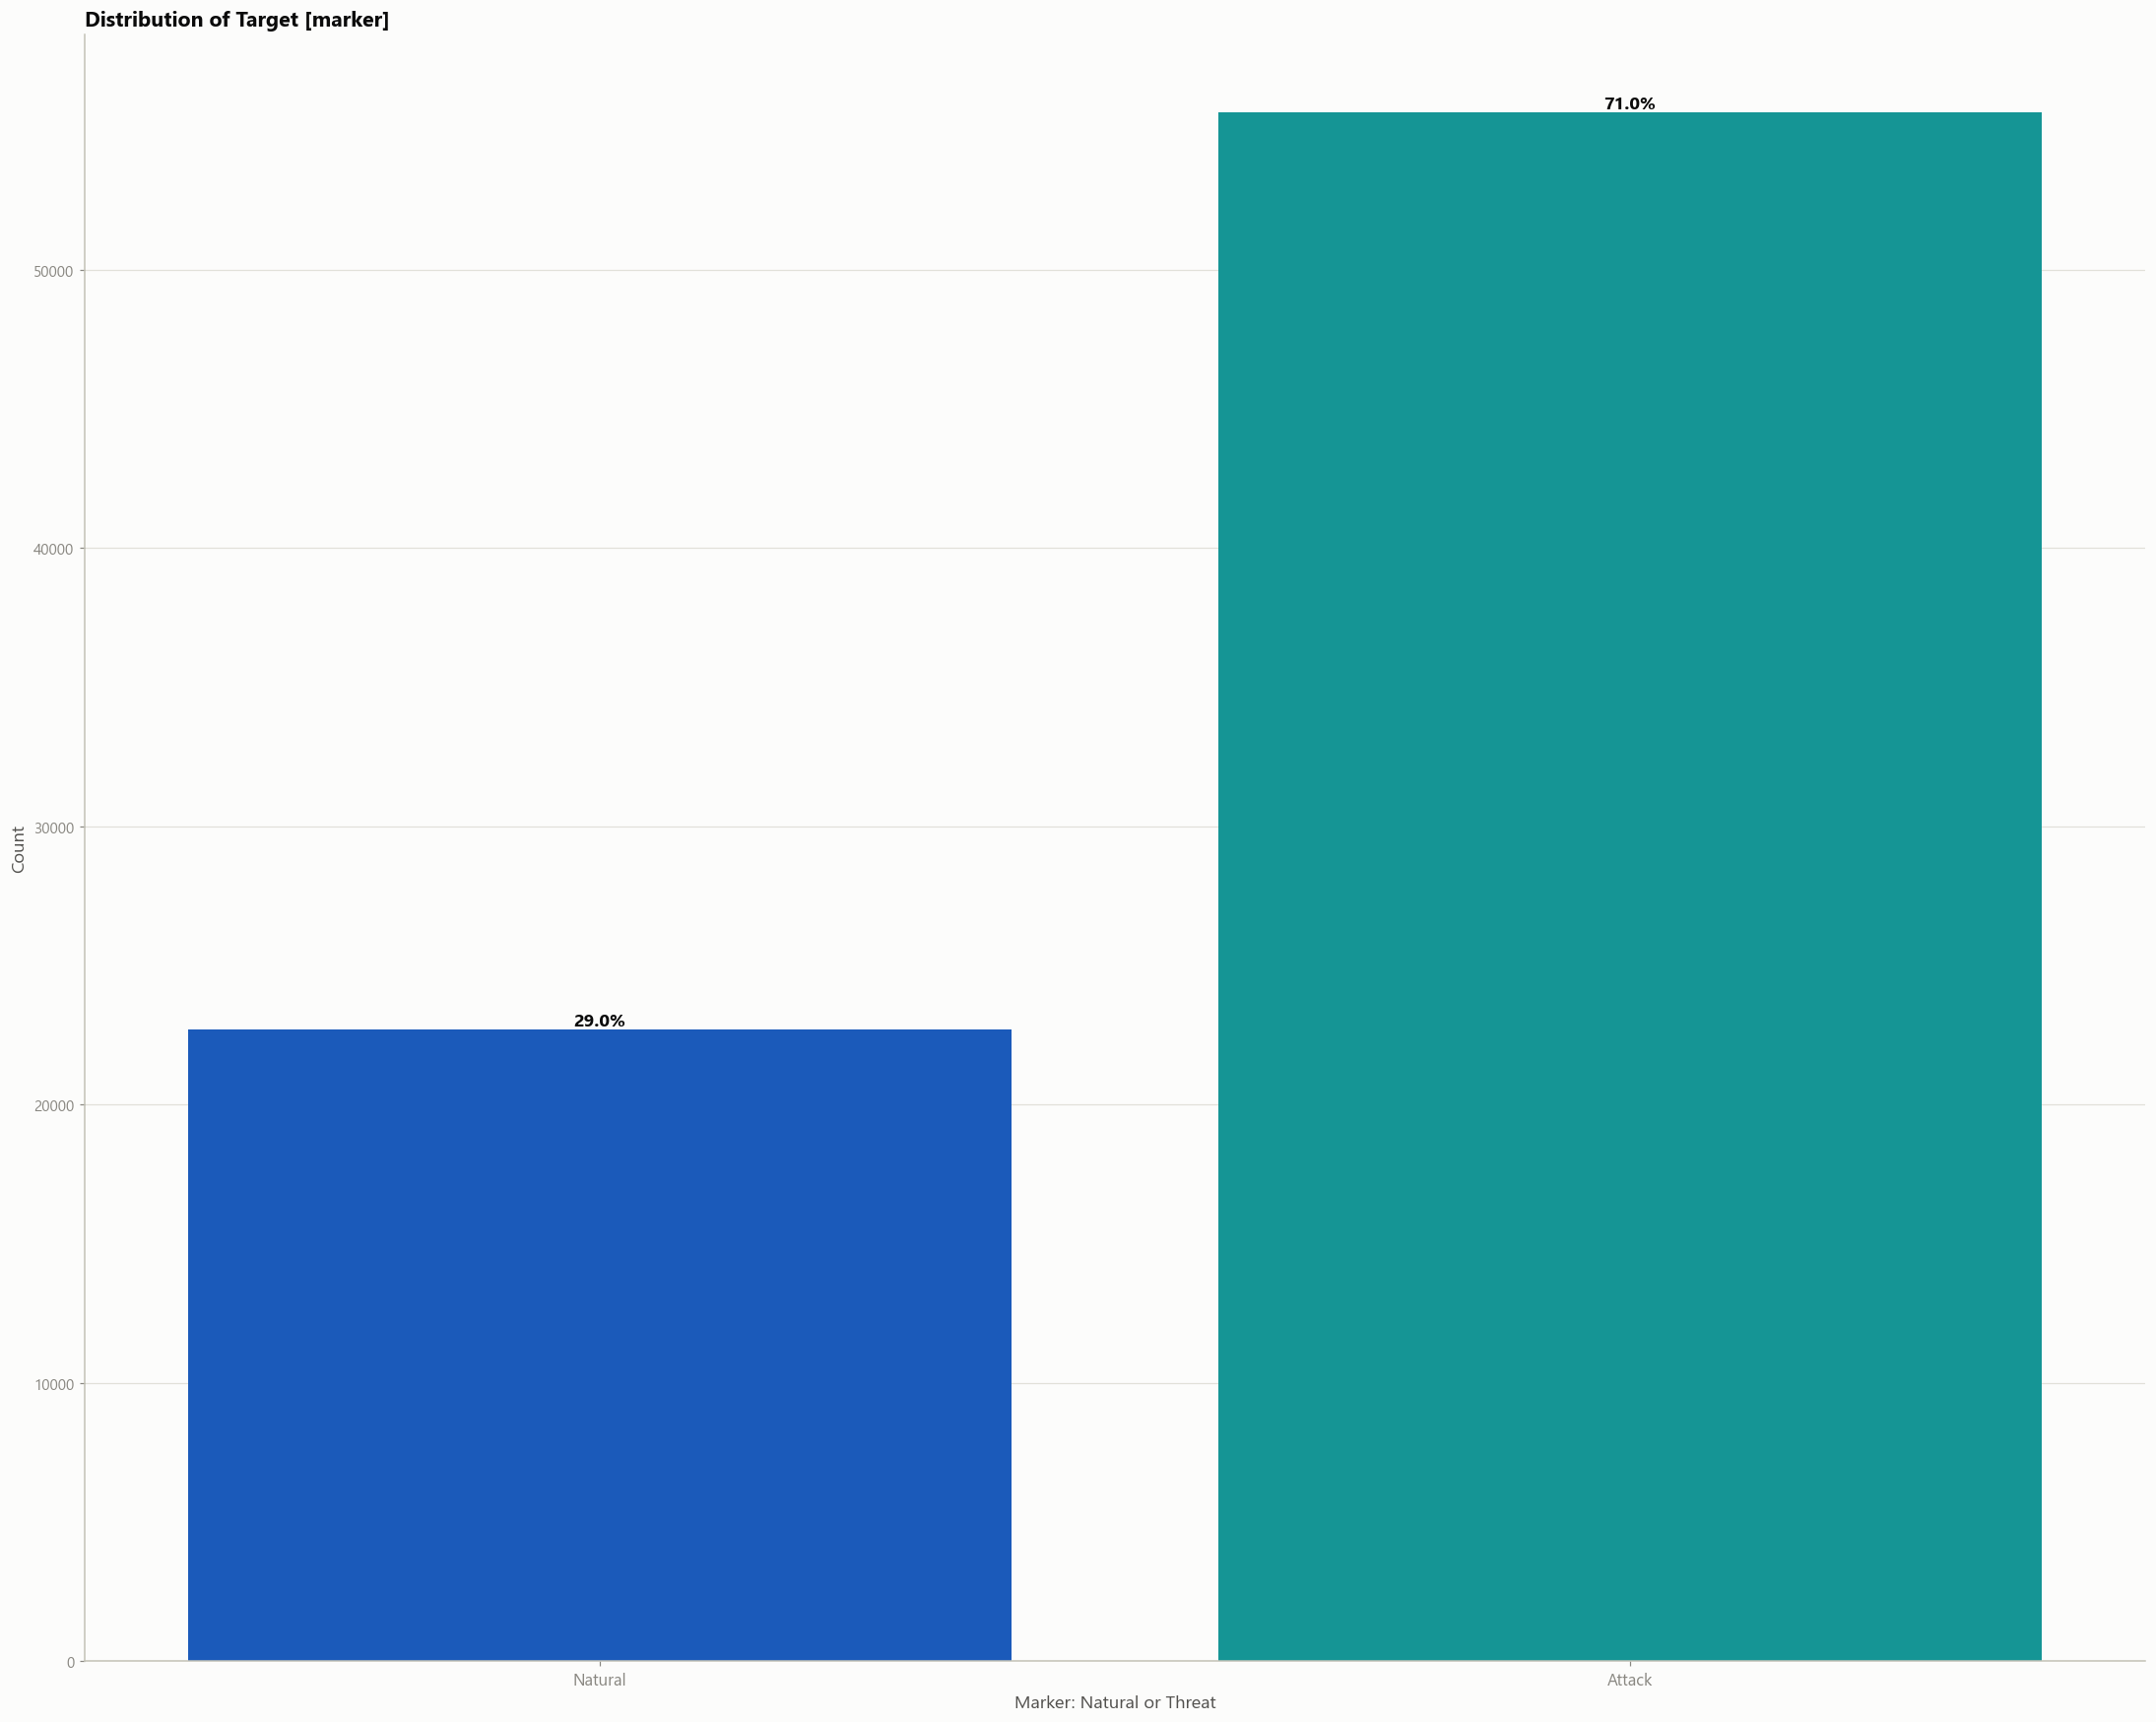

WindowsPath('figures/fig1_class_distribution.png')

In [9]:
# Class proportions
import seaborn as sns
def annotate_bars(ax, series):
    total = len(series)
    for p in ax.patches:
        percentage = '{:.1f}%'.format(100 * p.get_height() / total)
        x = p.get_x() + p.get_width() / 2
        y = p.get_height()
        ax.annotate(
            percentage,
            (x, y),
            ha='center',
            va='bottom',
            fontsize=12,
            fontweight='bold'
        )

# Plot distribution of Outcome
fig, ax = plt.subplots(figsize=(20, 16))

sns.countplot(
    data=df,
    x='marker', 
    hue='marker',
    palette='winter',
    legend=False,
    ax=ax
)

annotate_bars(ax, df['marker'])

ax.set_title('Distribution of Target [marker]', fontsize=14, fontweight='bold') # Update
ax.set_xlabel('Marker: Natural or Threat', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Natural', 'Attack'], fontsize=11)

plt.tight_layout()
plt.show()

savefig(fig, "fig1_class_distribution")


WindowsPath('figures/fig2_impedance_by_class.png')

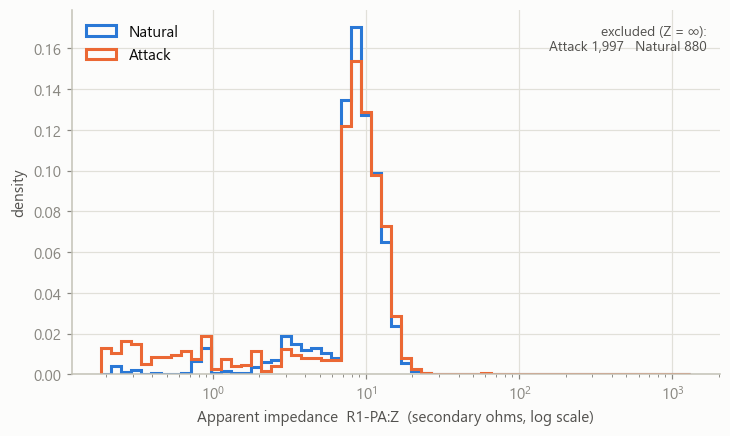

In [10]:
#Figure showing apparent impedance/resistance by class, Natural or Attack
fig, ax = plt.subplots(figsize = (7.6, 4.3))
z=df["R1-PA:Z"]; finite=np.isfinite(z)
#Use logspace so that 99% of the data doesn't land in bin 1
bins = np.logspace(np.log10(z[finite].min()), np.log10(z[finite].max()), 60)

for lab, col in [("Natural", C["s1"]), ("Attack", C["s2"])]:
    m = finite & (df["marker"] == lab)
    ax.hist(z[m], bins=bins, density=True, histtype="step", linewidth=2, color=col, label=lab)

ax.set_xscale("log")
ax.set_xlabel("Apparent impedance  R1-PA:Z  (secondary ohms, log scale)")
ax.set_ylabel("density")
ax.legend(loc="upper left")

n_inf = df[np.isposinf(z)]["marker"].value_counts()
ax.annotate(f"excluded (Z = ∞):\nAttack {n_inf['Attack']:,}   Natural {n_inf['Natural']:,}",
            xy=(0.98, 0.96), xycoords="axes fraction", ha="right", va="top",
            fontsize=9, color=C["ink2"])
savefig(fig, "fig2_impedance_by_class")


WindowsPath('figures/fig3_breaker_open_evidence.png')

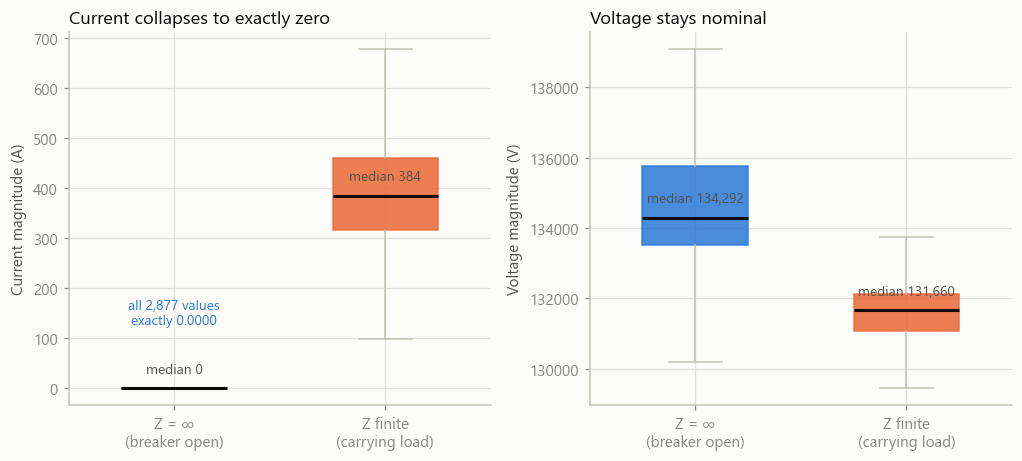

In [11]:
#Figures demonstrating how current drops to exactly 0.000, (not just extremely small, EXACTLY zero)
#while voltage stays nominal - the result of a breaker opening
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.3))
inf_r = np.isposinf(df["R1-PA:Z"])

for ax, col, ylab, title in [
        (axes[0], "R1-PM4:I", "Current magnitude (A)", "Current collapses to exactly zero"),
        (axes[1], "R1-PM1:V", "Voltage magnitude (V)", "Voltage stays nominal")]:
    data = [df.loc[inf_r, col].values, df.loc[~inf_r, col].values]
    bp = ax.boxplot(data,
                    tick_labels=["Z = ∞\n(breaker open)", "Z finite\n(carrying load)"],
                    patch_artist=True, showfliers=False, widths=0.5,
                    medianprops=dict(color=C["ink"], linewidth=2),
                    whiskerprops=dict(color=C["axis"]), capprops=dict(color=C["axis"]))
    for patch, c in zip(bp["boxes"], [C["s1"], C["s2"]]):
        patch.set_facecolor(c); patch.set_edgecolor(c); patch.set_alpha(0.85)
    ax.set_ylabel(ylab); ax.set_title(title)
    for i, d in enumerate(data, start=1):
        ax.annotate(f"median {np.median(d):,.0f}", xy=(i, np.median(d)), xytext=(0, 10),
                    textcoords="offset points", ha="center", fontsize=9, color=C["ink2"])

axes[0].annotate(f"all {int(inf_r.sum()):,} values\nexactly 0.0000", xy=(1, 0), xytext=(0, 42),
                 textcoords="offset points", ha="center", fontsize=9, color=C["s1"])
fig.tight_layout()
savefig(fig, "fig3_breaker_open_evidence")

## 6. Feature policy

Two groups of columns are excluded from all models. Both exclusions are tested rather than
assumed.

In [12]:
# Test whether the 12 cyber-log columns carry signal, by fitting a model on LOG_COLS ALONE.
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

sub = df.sample(12_000, random_state=RANDOM_STATE)
X_log, y_log_test = sub[LOG_COLS], (sub["marker"] == "Attack").astype(int)

rf    = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
dummy = DummyClassifier(strategy="most_frequent")

for name, model in [("logs-only RF", rf), ("always-predict-Attack", dummy)]:
    acc = cross_val_score(model, X_log, y_log_test, cv=5, scoring="accuracy").mean()
    f1  = cross_val_score(model, X_log, y_log_test, cv=5, scoring="f1_macro").mean()
    print(f"{name:24s} accuracy={acc:.4f}  macro_f1={f1:.4f}")

y_full = (df["marker"] == "Attack")
for c in LOG_COLS:
    pos = int((df[c] == 1).sum())
    rate = y_full[df[c] == 1].mean() if pos else float("nan")
    print(f"{c:20s} positives={pos:5d}  P(Attack|{c}=1)={rate:.3f}")


logs-only RF             accuracy=0.7158  macro_f1=0.4501
always-predict-Attack    accuracy=0.7146  macro_f1=0.4168
control_panel_log1   positives=    3  P(Attack|control_panel_log1=1)=0.333
control_panel_log2   positives=    3  P(Attack|control_panel_log2=1)=0.333
control_panel_log3   positives=    2  P(Attack|control_panel_log3=1)=0.000
control_panel_log4   positives=    2  P(Attack|control_panel_log4=1)=0.000
relay1_log           positives= 2815  P(Attack|relay1_log=1)=0.692
relay2_log           positives= 2072  P(Attack|relay2_log=1)=0.565
relay3_log           positives= 2077  P(Attack|relay3_log=1)=0.548
relay4_log           positives= 2790  P(Attack|relay4_log=1)=0.653
snort_log1           positives=    4  P(Attack|snort_log1=1)=1.000
snort_log2           positives=    4  P(Attack|snort_log2=1)=0.750
snort_log3           positives=    7  P(Attack|snort_log3=1)=1.000
snort_log4           positives=    6  P(Attack|snort_log4=1)=1.000


In [13]:
y = (df["marker"] == "Attack").astype(int)
#source_file as primary grouping, see section 7 for discussion of why this is necessary
groups = GROUPINGS["source_file"]        
X_wide = df[PMU_COLS].copy()

assert X_wide.shape[1] == 112
assert not any(("log" in c) or c.endswith(":S") for c in X_wide.columns)

print(f"X_wide {X_wide.shape}  (+4 open-breaker flags added per-fold -> 116 model inputs)")
print(f"y      {y.shape}, positive (Attack) rate {y.mean():.4f}")
print(f"groups {groups.nunique()} blocks")

X_wide (78377, 112)  (+4 open-breaker flags added per-fold -> 116 model inputs)
y      (78377,), positive (Attack) rate 0.7102
groups 15 blocks


### **Feature Policy Justification**

1. **12 cyber-log columns**: The dataset includes columns that are derived from what computers and network noticed, grouped into the families of `control_panel_log`, `snort_log`, and `relay*_log` (* for relays 1-4). Not only are these features not PMU-derived as the research question looks to discover, but they don't carry meaningful signal when it comes to model training. Above, the output shows that the log columns by themselves produced an accuracy of only 0.0012 higher than guessing "Attack" every time. F1 for the RF was 0.45 compared to 0.417 on the constant predictor, but that can be attributed to the RandomForest Classifier learning from the positive values in the relay_log columns and being able to distinguish when the instance was Natural rather than an Attack. In fact, as the output above shows, P(Attack | relay_log=1) ranges 0.548–0.692, all below the 0.715 base rate, so a relay log firing makes an attack less likely than knowing nothing. The other log columns, such as `snort_log`, are highly accurate, with P(Attack | snort_log=1) = 1.000, but the feature itself isn't informative because it only fires 4 times across 78K instances. The test above even included the leaky random split, allowing the RF to essentially memorize the correct answers from columns that were very similar in the original dataset when split into train & test, and it still only produced an accuracy of 0.0012 higher. Overall, these features aren't carrying meaningful signal relative to the research question itself, so they are to be dropped for model training.
2. **Status word columns**: The dataset includes `R#:S` columns to display the bitfield representing the relay's status at any given time. However, these features only demonstrate the status of the relay after an event (eg. a trip) has happened, not if the trip was justified. Not only do these features not relate to PMU-derived measurements, but their scale and dtypes differ significantly across each column. Models like Logistic Regression would falsely interpret the numerical values of what is in reality a set of flags, not continuous values, as being "higher" or "lower" than one another, which would create false patterns in the models' understanding of the data. Including them would also make the Leave-One-Relay-Out test meaningless; the test assumes every feature means the same thing on every relay, and R4:S is float64 with negative values while R1:S is int64 with seven bitfield values. For these reasons, these columns are to be left out of model training in favor of their use as independent corroboration in section 4. 

## **7. Baseline models**

Every model is evaluated under **two protocols**:

- **Random stratified split**: matches how results on this dataset are conventionally reported,
  and so is the number comparable to published work. Section 4 established that rows are
  contiguous and 99.9% autocorrelated, so this protocol leaks by construction.
- **StratifiedGroupKFold grouped by `source_file`**: an entire recording session is either
  wholly in train or wholly in test, so no near-duplicate neighbour spans the split. This is the
  honest number and the headline.

`source_file` is the primary grouping because its folds come out near the 71/29 population
balance, whereas the 75 label-pure blocks are large and single-class, so grouping on them
produces folds swinging between roughly 54% and 83% Attack. That imbalance depresses macro-F1
for reasons that have nothing to do with generalization. 

In [14]:
def fit_inf_policy(X_train: pd.DataFrame, z_cols, quantile: float = 0.999) -> dict:
    #Compute the cap as the given quantile of that column's FINITE values in X_train
    #Fit on training only so that the test fold doesn't influence how the training fold is transformed
    policy = {}
    for c in z_cols:
        col = X_train[c]
        finite = col[np.isfinite(col)]          # the critical guard
        policy[c] = float(finite.quantile(quantile))
    return policy

def apply_inf_policy(X: pd.DataFrame, policy: dict, z_cols) -> pd.DataFrame:
    #Implement the flag and cap policy.
    #New DataFrame is returned so that the original X isn't mutated.
    out = X.copy()                              
    for c in z_cols:
        cap = policy[c]
        out[f"{c}__open"] = np.isposinf(out[c]).astype(int)
        #Flag before capping, so that the model can learn that a breaker opened
        #and then the voltage/current collapsed to zero.   
        out[c] = out[c].clip(upper=cap)
    return out


In [15]:
#Evaluation harness. Both protocols refit the inf policy inside every fold
def _metrics(y_true, y_pred) -> dict:
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }


def eval_holdout(model, X, y, z_cols, test_size=0.25, seed=RANDOM_STATE):
    #Random stratified row split
    #Leaky by construction, but this method is necessary for comparability
    #with published results on this dataset.
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=seed)
    policy = fit_inf_policy(X_tr, z_cols)
    X_tr = apply_inf_policy(X_tr, policy, z_cols)
    X_te = apply_inf_policy(X_te, policy, z_cols)
    fitted = clone(model).fit(X_tr, y_tr)
    pred = fitted.predict(X_te)
    return _metrics(y_te, pred), confusion_matrix(y_te, pred)


def eval_grouped(model, X, y, groups, z_cols, n_splits=5):
    #StatifiedGroupKFold over contiguous label-run blocks to test the honest protocol
    #Each row is predicted on a model that never saw its block during training
    #Out-of-fold metrics are returned.
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    groups = pd.Series(groups).reset_index(drop=True)
    oof = np.empty(len(y), dtype=int)
    for tr_idx, te_idx in cv.split(X, y, groups):
        # the wiring check: no group may appear on both sides of the split
        assert not set(groups.iloc[tr_idx]) & set(groups.iloc[te_idx]), "group leak"
        X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
        policy = fit_inf_policy(X_tr, z_cols)
        fitted = clone(model).fit(apply_inf_policy(X_tr, policy, z_cols), y.iloc[tr_idx])
        oof[te_idx] = fitted.predict(apply_inf_policy(X_te, policy, z_cols))
    return _metrics(y, oof), confusion_matrix(y, oof)


def summarize(results: dict) -> pd.DataFrame:
    return (pd.DataFrame(results).T
            .rename_axis(["model", "protocol"])
            .round(4)
            .sort_values("macro_f1", ascending=False))

In [16]:
#Define three baseline models
MODELS = {
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": xgb.XGBClassifier(
        n_estimators=300, learning_rate=0.1, max_depth=6, tree_method="hist",
        random_state=RANDOM_STATE, n_jobs=-1, eval_metric="logloss"),
}

results, cms = {}, {}
for name, model in MODELS.items():
    for proto in ("random", "grouped"):
        if proto == "random":
            m, cm = eval_holdout(model, X_wide, y, Z_COLS)
        else:
            m, cm = eval_grouped(model, X_wide, y, groups, Z_COLS)
        results[(name, proto)] = m
        cms[(name, proto)] = cm
        print(f"{name:22s} {proto:8s} macro_f1={m['macro_f1']:.4f}  acc={m['accuracy']:.4f}")

display(summarize(results))

Logistic Regression    random   macro_f1=0.4763  acc=0.7135
Logistic Regression    grouped  macro_f1=0.4739  acc=0.7126
Random Forest          random   macro_f1=0.8994  acc=0.9213
Random Forest          grouped  macro_f1=0.6004  acc=0.7055
XGBoost                random   macro_f1=0.7624  acc=0.8300
XGBoost                grouped  macro_f1=0.6049  acc=0.7219


accuracy  precision  recall  macro_f1
model               protocol                                       
Random Forest       random      0.9213     0.9175  0.9770    0.8994
XGBoost             random      0.8300     0.8281  0.9598    0.7624
                    grouped     0.7219     0.7590  0.8913    0.6049
Random Forest       grouped     0.7055     0.7589  0.8578    0.6004
Logistic Regression random      0.7135     0.7200  0.9761    0.4763
                    grouped     0.7126     0.7194  0.9760    0.4739

In [17]:
#See if each different type of grouping (source_file, block, event) gives similar 
#results for the best model
best_name = max((k for k in results if k[1] == "grouped"),
                key=lambda k: results[k]["macro_f1"])[0]
best_model = MODELS[best_name]
print(f"best model under the grouped protocol: {best_name}\n")

sens = {}
m, _ = eval_holdout(best_model, X_wide, y, Z_COLS)
sens["random split (leaky)"] = {"n_groups": np.nan, **m}

for gname, gvals in GROUPINGS.items():
    m, _ = eval_grouped(best_model, X_wide, y, gvals, Z_COLS)
    sens[f"grouped by {gname}"] = {"n_groups": gvals.nunique(), **m}

sens_df = pd.DataFrame(sens).T[["n_groups", "accuracy", "macro_f1"]].astype(float).round(4)
display(sens_df)

g = sens_df.loc[sens_df.index.str.startswith("grouped"), "macro_f1"]
print(f"\nspread across the three groupings: {g.min():.4f} – {g.max():.4f} "
      f"(range {g.max()-g.min():.4f})")

best model under the grouped protocol: XGBoost



,n_groups,accuracy,macro_f1
random split (leaky),NaN,0.8300,0.7624
grouped by source_file,15.0,0.7219,0.6049
grouped by block,75.0,0.7038,0.5806
grouped by event,2625.0,0.7204,0.5989



spread across the three groupings: 0.5806 – 0.6049 (range 0.0243)


WindowsPath('figures/fig4_baseline_comparison.png')

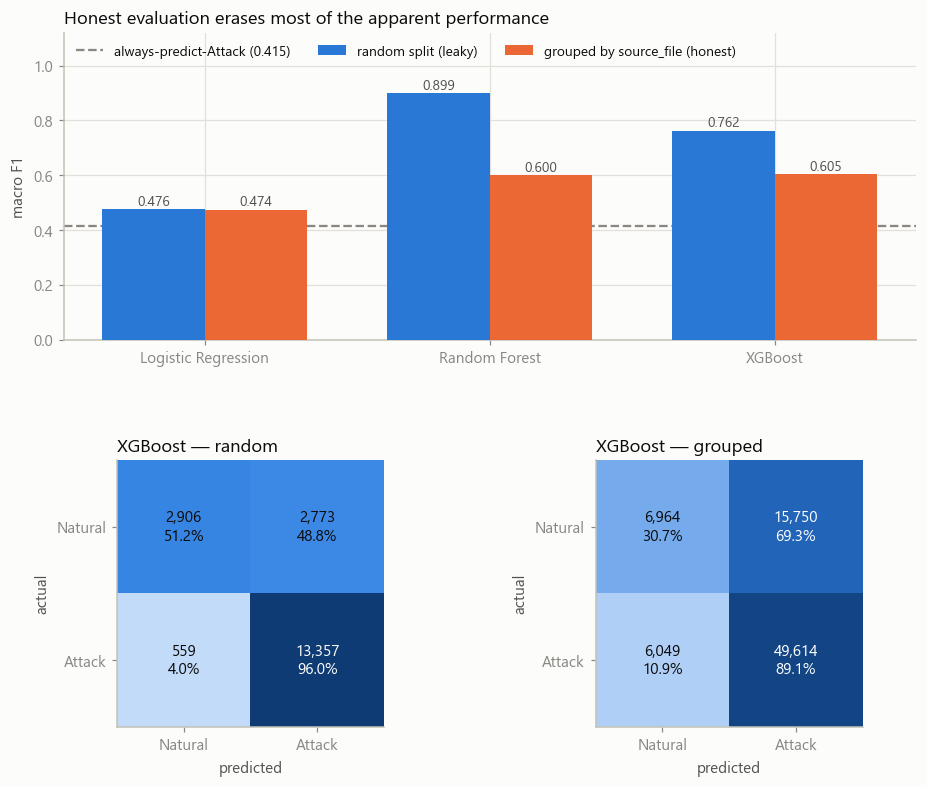

In [18]:
#Confusion matrices for best model under both protocols
#Comparisons per model for each protocol
from matplotlib.colors import LinearSegmentedColormap

CONST_F1 = 0.4153
best = best_name
names = list(MODELS)

fig = plt.figure(figsize=(10, 8.2))
gs = fig.add_gridspec(2, 2, height_ratios=[1.15, 1], hspace=0.42, wspace=0.28)

#top bar chart of macro F1 scores
ax = fig.add_subplot(gs[0, :])
xpos, w = np.arange(len(names)), 0.36
for k, (proto, col, lab) in enumerate([
        ("random",  C["s1"], "random split (leaky)"),
        ("grouped", C["s2"], "grouped by source_file (honest)")]):
    vals = [results[(n, proto)]["macro_f1"] for n in names]
    bars = ax.bar(xpos + (k - 0.5) * w, vals, w, color=col, label=lab, zorder=3)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.014, f"{v:.3f}",
                ha="center", fontsize=9, color=C["ink2"])

ax.axhline(CONST_F1, ls="--", lw=1.5, color=C["muted"], zorder=2,
           label=f"always-predict-Attack ({CONST_F1:.3f})")
ax.set_xticks(xpos, names); ax.set_ylabel("macro F1"); ax.set_ylim(0, 1.12)
ax.set_title("Honest evaluation erases most of the apparent performance")
ax.legend(loc="upper left", ncol=3, fontsize=9)

cmap = LinearSegmentedColormap.from_list("seqblue", SEQ_BLUE)
for j, proto in enumerate(["random", "grouped"]):
    a = fig.add_subplot(gs[1, j])
    cm = cms[(best, proto)]
    cmn = cm / cm.sum(axis=1, keepdims=True)      # row-normalise = per-class recall
    a.imshow(cmn, cmap=cmap, vmin=0, vmax=1); a.grid(False)
    a.set_xticks([0, 1], ["Natural", "Attack"]); a.set_yticks([0, 1], ["Natural", "Attack"])
    a.set_xlabel("predicted"); a.set_ylabel("actual"); a.set_title(f"{best} — {proto}")
    for r in range(2):
        for c_ in range(2):
            a.text(c_, r, f"{cm[r, c_]:,}\n{cmn[r, c_]:.1%}", ha="center", va="center",
                   fontsize=10, color="#ffffff" if cmn[r, c_] > 0.55 else C["ink"])

savefig(fig, "fig4_baseline_comparison")

In [19]:
spw = float((y == 0).sum() / (y == 1).sum())
WEIGHTED = {
    "Logistic Regression (bal)": Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced",
                                   random_state=RANDOM_STATE)),
    ]),
    "Random Forest (bal)": RandomForestClassifier(
        n_estimators=200, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost (spw)": xgb.XGBClassifier(
        n_estimators=300, learning_rate=0.1, max_depth=6, tree_method="hist",
        scale_pos_weight=spw, random_state=RANDOM_STATE, n_jobs=-1,
        eval_metric="logloss"),
}
results_weighted, cms_weighted = {}, {}
for name, model in WEIGHTED.items():
    for proto in ("random", "grouped"):
        if proto == "random":
            m, cm = eval_holdout(model, X_wide, y, Z_COLS)
        else:
            m, cm = eval_grouped(model, X_wide, y, groups, Z_COLS)
        results_weighted[(name, proto)] = m
        cms_weighted[(name, proto)] = cm
        print(f"{name:22s} {proto:8s} macro_f1={m['macro_f1']:.4f}  acc={m['accuracy']:.4f}")

display(summarize(results_weighted))

Logistic Regression (bal) random   macro_f1=0.5794  acc=0.5885
Logistic Regression (bal) grouped  macro_f1=0.5691  acc=0.5779
Random Forest (bal)    random   macro_f1=0.8971  acc=0.9202
Random Forest (bal)    grouped  macro_f1=0.5957  acc=0.7050
XGBoost (spw)          random   macro_f1=0.7922  acc=0.8143
XGBoost (spw)          grouped  macro_f1=0.6064  acc=0.6503


accuracy  precision  recall  macro_f1
model                     protocol                                       
Random Forest (bal)       random      0.9202     0.9130  0.9811    0.8971
XGBoost (spw)             random      0.8143     0.9259  0.8027    0.7922
                          grouped     0.6503     0.7890  0.6929    0.6064
Random Forest (bal)       grouped     0.7050     0.7564  0.8624    0.5957
Logistic Regression (bal) random      0.5885     0.8418  0.5179    0.5794
                          grouped     0.5779     0.8331  0.5072    0.5691

In [20]:
#See if each different type of grouping (source_file, block, event) gives similar 
#results for the best model for WEIGHTED models
best_name_weighted = max((k for k in results_weighted if k[1] == "grouped"),
                         key=lambda k: results_weighted[k]["macro_f1"])[0]
best_model_weighted = WEIGHTED[best_name_weighted]
print(f"best model under the grouped protocol: {best_name_weighted}\n")

sens = {}
m, _ = eval_holdout(best_model_weighted, X_wide, y, Z_COLS)
sens["random split (leaky)"] = {"n_groups": np.nan, **m}

for gname, gvals in GROUPINGS.items():
    m, _ = eval_grouped(best_model_weighted, X_wide, y, gvals, Z_COLS)
    sens[f"grouped by {gname}"] = {"n_groups": gvals.nunique(), **m}

sens_df = pd.DataFrame(sens).T[["n_groups", "accuracy", "macro_f1"]].astype(float).round(4)
display(sens_df)

g = sens_df.loc[sens_df.index.str.startswith("grouped"), "macro_f1"]
print(f"\nspread across the three groupings: {g.min():.4f} – {g.max():.4f} "
      f"(range {g.max()-g.min():.4f})")

best model under the grouped protocol: XGBoost (spw)



,n_groups,accuracy,macro_f1
random split (leaky),NaN,0.8143,0.7922
grouped by source_file,15.0,0.6503,0.6064
grouped by block,75.0,0.6358,0.5896
grouped by event,2625.0,0.6566,0.6132



spread across the three groupings: 0.5896 – 0.6132 (range 0.0236)


WindowsPath('figures/fig4_weighted_comparison.png')

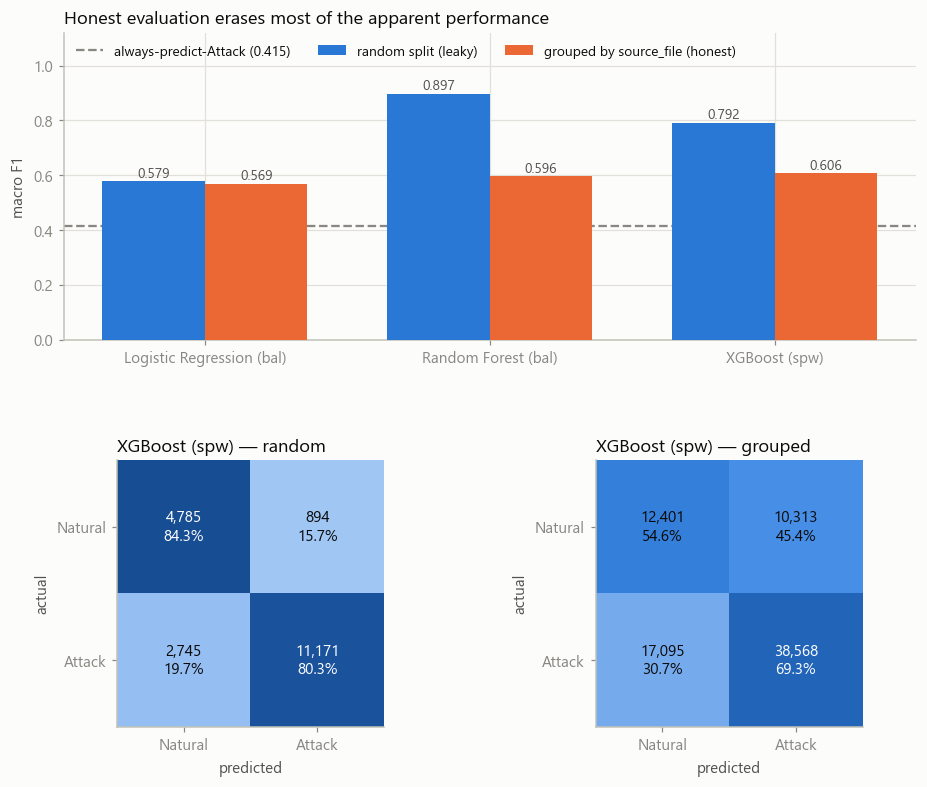

In [21]:
#Confusion matrices for best model under both protocols
#Comparisons per model for each protocol
from matplotlib.colors import LinearSegmentedColormap

CONST_F1 = 0.4153
best = best_name_weighted
names = list(WEIGHTED)

fig = plt.figure(figsize=(10, 8.2))
gs = fig.add_gridspec(2, 2, height_ratios=[1.15, 1], hspace=0.42, wspace=0.28)

ax = fig.add_subplot(gs[0, :])
xpos, w = np.arange(len(names)), 0.36
for k, (proto, col, lab) in enumerate([
        ("random",  C["s1"], "random split (leaky)"),
        ("grouped", C["s2"], "grouped by source_file (honest)")]):
    vals = [results_weighted[(n, proto)]["macro_f1"] for n in names]
    bars = ax.bar(xpos + (k - 0.5) * w, vals, w, color=col, label=lab, zorder=3)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.014, f"{v:.3f}",
                ha="center", fontsize=9, color=C["ink2"])

ax.axhline(CONST_F1, ls="--", lw=1.5, color=C["muted"], zorder=2,
           label=f"always-predict-Attack ({CONST_F1:.3f})")
ax.set_xticks(xpos, names); ax.set_ylabel("macro F1"); ax.set_ylim(0, 1.12)
ax.set_title("Honest evaluation erases most of the apparent performance")
ax.legend(loc="upper left", ncol=3, fontsize=9)

cmap = LinearSegmentedColormap.from_list("seqblue", SEQ_BLUE)
for j, proto in enumerate(["random", "grouped"]):
    a = fig.add_subplot(gs[1, j])
    cm = cms_weighted[(best, proto)]
    cmn = cm / cm.sum(axis=1, keepdims=True)      # row-normalise = per-class recall
    a.imshow(cmn, cmap=cmap, vmin=0, vmax=1); a.grid(False)
    a.set_xticks([0, 1], ["Natural", "Attack"]); a.set_yticks([0, 1], ["Natural", "Attack"])
    a.set_xlabel("predicted"); a.set_ylabel("actual"); a.set_title(f"{best} — {proto}")
    for r in range(2):
        for c_ in range(2):
            a.text(c_, r, f"{cm[r, c_]:,}\n{cmn[r, c_]:.1%}", ha="center", va="center",
                   fontsize=10, color="#ffffff" if cmn[r, c_] > 0.55 else C["ink"])

savefig(fig, "fig4_weighted_comparison")

## Baseline Model Interpretation
XGBoost overall performed the best, producing the highest macro-F1 score of 0.6049 when grouped by `source_file`, relative to the other models. XGBoost had a gap of 0.157 comparing the random split macro-F1 (0.762) to the best-performing grouping method, by `source_file` (0.605). This gap implies that published work on this dataset that use the random split are inflated by adjacency leakage. In regard to the effect of class weighting, the results showed a 0.0015 difference between non-weighted and weighted XGBoost, while the weighted model in the random split protocol achieved 0.7922 macro-F1 compared to 0.7624 on the non-weighted model. Logistic Regression overall didn't appear to be affected by leakage with a total macro-F1 difference of 0.002 between the grouping protocol and the random split protocol, which makes sense because Logistic Regression doesn't rely on individual rows.  

## **8. Relay-generic representation**

The research question asks what a **single relay** must compute in real time. The wide format
cannot answer that: its columns are relay-specific, so a model trained on it learns "R1's
impedance" rather than "impedance."

Reshaping to long form makes one row = **one relay's view of one snapshot**, with features
renamed to relay-generic names (`PA:Z` rather than `R1-PA:Z`). A model trained on some relays can
then be applied directly to another. 78,377 × 4 = **313,508 rows × 28 features**.

In [22]:
def to_long(frame: pd.DataFrame, generic_feats=GENERIC_PMU_28) -> pd.DataFrame:
    #Wide (one row = one system snapshot) -> long (one row = one relay's view).

    #Feature columns are renamed to relay-generic names, so relay identity lives in
    #the relay_id column rather than being baked into column names. block_id and
    #orig_row are carried through so grouped CV and leave-one-relay-out can both
    #respect the original row structure.
    
    parts = []
    for r in RELAYS:
        rename = {wide(r, g): g for g in generic_feats}
        part = frame[list(rename)].rename(columns=rename)
        part["relay_id"] = r
        part["marker"] = frame["marker"].to_numpy()
        part["source_file"] = frame["source_file"].to_numpy()
        part["block_id"] = frame["block_id"].to_numpy()
        part["event_id"] = frame["event_id"].to_numpy()
        part["orig_row"] = frame.index.to_numpy()
        parts.append(part)
    return pd.concat(parts, ignore_index=True)


long_df = to_long(df)

assert long_df.shape[0] == 78377 * 4 == 313508
assert (long_df["relay_id"].value_counts() == 78377).all()
assert list(long_df.columns[:28]) == GENERIC_PMU_28, "feature order drifted"

X_long = long_df[GENERIC_PMU_28].copy()
y_long = (long_df["marker"] == "Attack").astype(int)
g_long = long_df["source_file"]        
Z_LONG = ["PA:Z"]                      

print(f"long frame  : {long_df.shape}")
print(f"features    : {len(GENERIC_PMU_28)} relay-generic (+1 open flag -> 29 model inputs)")
print(f"inf cells   : {int(np.isposinf(X_long['PA:Z']).sum())} in PA:Z")

long frame  : (313508, 34)
features    : 28 relay-generic (+1 open flag -> 29 model inputs)
inf cells   : 10906 in PA:Z


## **9. Format control**

Before attributing anything to relay transfer, the cost of the reshape alone should be established. This
refits the best model on the long frame under the same two protocols. Without this number, a
drop in section 12 can't be separated from the change of representation.

In [23]:

# Refit the best section-7 model (XGBoost) on (X_long, y_long, g_long) with Z_LONG as the z_cols,
# under BOTH eval_holdout and eval_grouped. 

best_model = MODELS["XGBoost"]
LONG_KEY = "XGBoost (long, 28 feat)"

for proto in ("random", "grouped"):
    if proto == "random":
        m, cm = eval_holdout(best_model, X_long, y_long, Z_LONG)
    else:
        m, cm = eval_grouped(best_model, X_long, y_long, g_long, Z_LONG)
    results[(LONG_KEY, proto)] = m
    cms[(LONG_KEY, proto)] = cm
    print(f"long {proto:8s} macro_f1={m['macro_f1']:.4f}  acc={m['accuracy']:.4f}")

display(summarize(results))

long random   macro_f1=0.6052  acc=0.7612
long grouped  macro_f1=0.5119  acc=0.7017


accuracy  precision  recall  macro_f1
model                   protocol                                       
Random Forest           random      0.9213     0.9175  0.9770    0.8994
XGBoost                 random      0.8300     0.8281  0.9598    0.7624
XGBoost (long, 28 feat) random      0.7612     0.7567  0.9785    0.6052
XGBoost                 grouped     0.7219     0.7590  0.8913    0.6049
Random Forest           grouped     0.7055     0.7589  0.8578    0.6004
XGBoost (long, 28 feat) grouped     0.7017     0.7255  0.9330    0.5119
Logistic Regression     random      0.7135     0.7200  0.9761    0.4763
                        grouped     0.7126     0.7194  0.9760    0.4739

### **Format Control Interpretation**
This section was intended to serve as a control for the section 12 LORO test to be done. When the feature set is reduced to 28 relay-generic columns and the number of instances jumps to 313508, the best model, XGBoost, performs noticeably worse. More specifically, on the random split protocol, with the data prior to the format control, XGBoost achieves 0.7624 macro F1 score, while it only achieves 0.6052 with the format control data. Furthermore, the grouped XGBoost on the 28 feature set can only get to 0.5119 macro F1, while the grouped XGBoost on the original data achieves 0.6049 macro F1. Overall, these results are to be expected, as the model becomes restricted to seeing the "perspective" of only 1 relay per instance rather than getting a more complete picture with all of the features in the original dataset. In essence, these results go to show that the reshape alone costs 0.093 macro-F1 under the honest protocol (0.6049 -> 0.5119), and that has to be subtracted before anything can be attributed to relay transfer in section 12. 

## **10. Feature importance**

Context on how each feature importance evaluation works: 
Permutation importance measures the drop in score when a
feature is scrambled (so correlated features share credit and can both look unimportant), while
SHAP attributes each individual prediction (so it can surface a feature that matters strongly
for a subset of rows).

In [24]:
# Permutation importance on the long frame
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tr_idx, te_idx = next(cv.split(X_long, y_long, g_long))

pol  = fit_inf_policy(X_long.iloc[tr_idx], Z_LONG)
X_tr = apply_inf_policy(X_long.iloc[tr_idx], pol, Z_LONG)
X_te = apply_inf_policy(X_long.iloc[te_idx], pol, Z_LONG)
y_tr, y_te = y_long.iloc[tr_idx], y_long.iloc[te_idx]

imp_model = clone(MODELS["XGBoost"]).fit(X_tr, y_tr)
FEATS = list(X_tr.columns)                 
print(f"fitted on {X_tr.shape}, importance measured on held-out {X_te.shape}")

rng = np.random.default_rng(RANDOM_STATE)
sub = rng.choice(len(X_te), min(50_000, len(X_te)), replace=False)

pi = permutation_importance(imp_model, X_te.iloc[sub], y_te.iloc[sub],
                            scoring="f1_macro", n_repeats=5,
                            random_state=RANDOM_STATE, n_jobs=-1)

perm_rank = pd.Series(pi.importances_mean, index=FEATS).sort_values(ascending=False)
perm_std  = pd.Series(pi.importances_std,  index=FEATS)
display(pd.DataFrame({"mean_drop": perm_rank, "std": perm_std[perm_rank.index]}).head(12).round(5))

fitted on (250544, 29), importance measured on held-out (62964, 29)


,mean_drop,std
PM5:I,0.02586,0.00073
PM4:I,0.01552,0.00049
PA1:VH,0.01308,0.00068
PA:ZH,0.00959,0.00047
PA:Z,0.00716,0.00095
F,0.00637,0.00117
PM11:I,0.00634,0.00046
PA2:VH,0.00589,0.00066
PM1:V,0.00563,0.00063
PM2:V,0.00475,0.00122


SHAP values: (20000, 29)


PM2:V     0.29637
PM1:V     0.20459
PM5:I     0.14649
F         0.12459
PA3:VH    0.11038
PM4:I     0.09249
PA2:VH    0.08779
PA:ZH     0.08397
PA:Z      0.07895
PM3:V     0.06467
PA5:IH    0.05749
PM7:V     0.05236
dtype: float32

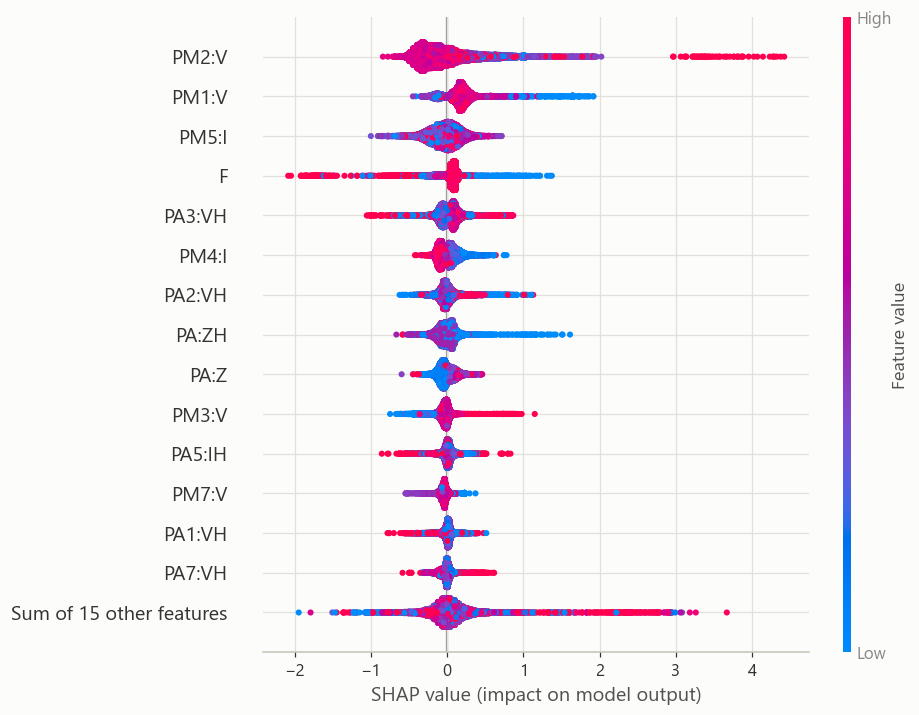

In [25]:
# SHAP analysis on the same fitted model.
rng = np.random.default_rng(RANDOM_STATE)
shap_sub  = X_te.iloc[rng.choice(len(X_te), min(20_000, len(X_te)), replace=False)]
explainer = shap.TreeExplainer(imp_model)
sv = explainer(shap_sub)
print("SHAP values:", sv.values.shape)

plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False)
savefig(plt.gcf(), "fig5_shap_summary")

shap_rank = pd.Series(np.abs(sv.values).mean(axis=0),
                      index=shap_sub.columns).sort_values(ascending=False)
display(shap_rank.head(12).round(5))

In [26]:
# Comparison of the two analyses
from scipy.stats import spearmanr

cmp = pd.DataFrame({"perm": perm_rank.rank(ascending=False).astype(int),
                    "shap": shap_rank.rank(ascending=False).astype(int)})
cmp["gap"] = (cmp["perm"] - cmp["shap"]).abs()
print(f"Spearman between the two rankings: {spearmanr(cmp['perm'], cmp['shap']).statistic:.3f}\n")

print("top 10 permutation:", list(perm_rank.head(10).index))
print("top 10 SHAP       :", list(shap_rank.head(10).index))
print("\nlargest disagreements:"); display(cmp.sort_values("gap", ascending=False).head(8))

for f in ["PA:Z", "PA:Z__open"]:
    print(f"{f:12s} perm rank {cmp.loc[f,'perm']:2d}/29   SHAP rank {cmp.loc[f,'shap']:2d}/29")

Spearman between the two rankings: 0.683

top 10 permutation: ['PM5:I', 'PM4:I', 'PA1:VH', 'PA:ZH', 'PA:Z', 'F', 'PM11:I', 'PA2:VH', 'PM1:V', 'PM2:V']
top 10 SHAP       : ['PM2:V', 'PM1:V', 'PM5:I', 'F', 'PA3:VH', 'PM4:I', 'PA2:VH', 'PA:ZH', 'PA:Z', 'PM3:V']

largest disagreements:


,perm,shap,gap
PM7:V,29,12,17
PA3:VH,18,5,13
PA1:VH,3,13,10
PM11:I,7,17,10
PA10:IH,13,22,9
PM2:V,10,1,9
PM10:I,24,16,8
PA4:IH,15,23,8


PA:Z         perm rank  5/29   SHAP rank  9/29
PA:Z__open   perm rank 20/29   SHAP rank 25/29


# **Feature Importance Interpretation**

- The **top feature** recognized by the permutation importance was `PM5:I`, while the most important feature under the SHAP analysis was `PM2: V`. For the permutation test, which takes the approach of shuffling the feature's column (and therefore changing its relationship the to target variable) and seeing how far the accuracy drops, it follows that current would be selected as highly important, because in most attacks involving a trip in the breaker (and as shown in the box plots above), impedance spikes up to infinity as current drops to zero. For the SHAP analysis, voltage gets flagged as the most important feature. This makes sense in the context of a protective relay, as changes in voltage signal give the model the context it needs across natural breaker trips and attacks to distinguish those two from one another. 

- In terms of `PA:Z`, the permutation test ranked it as **5th** overall, while SHAP scored it at **9th**. While prior work from MSU and ORNL typically had impedance ranked higher, prior worked used the wide format, where each of the four relays' impedances give the entire system an idea that a single relay's `PA:Z` cannot. Interestingly, neither test ranked `PA:Z__open` in the top 10 features (20th/29 for permutation test, 25th/29 for SHAP), meaning that the model detecting that a trip occurred was not as critical to its final prediction as other features.   

- The permutation test ranked **Frequency** (`F`) as 6th most important, while SHAP analysis ranked it at 4th. `DF` (how fast frequency was changing) did not make the top 10 features through either test. The fact that frequency was ranked so high demonstrates the system-wide aspect of frequency doing it's proper job - the model essentially uses frequency as a sanity check against other "changeable" measures on single relays like voltage or current, so if an attacker uses a False Data Injection Attack on one of those lines, the model can check that change in the data against the frequency to get a sense of if the instance is natural or an attack. On the other side of that coin, since frequency is system-wide, its response time is slow. That raises questions on the feature's viability for a detector meant to act between cycles.

- Under balanced conditions, voltage magnitudes across the three phases should be very similar; in fact, they are typically near duplicates. **Permutation explicitly punishes** this type of similarity, which is why features such as `PM1:V` or `PM3:V` are ranked lower in the permutation test than they are in the **SHAP analysis**, which doesn't have any mechanism to punish redundancy. This explains a difference in the two approaches' results for feature importance, as a feature such as `PM2:V` was ranked as first by SHAP but 10th by permutation. 

- Although section 3 implied that the decomposition with the sequence components (pairs 7-12) should be more telling, both tests showed `PM4:I`/`PM5:I` and `PM1:V`/`PM2:V` dominating. This can be attributed to the fact that sequence components isolate unbalanced conditions, so they'd matter more for asymmetric faults, which may be a minority of these instances.

## **11. Feature-reduction curve**

In [27]:
def reduction_curve(model, X, y, groups, ranking, ks, z_cols=Z_LONG) -> pd.DataFrame:
    #Macro-F1 under grouped CV as a function of feature-budget k
    rows = []
    for k in ks:
        feats = list(ranking[:k])
        # only pass z_cols that are actually in the feature set
        z = [c for c in z_cols if c in feats]     
        m, _ = eval_grouped(model, X[feats], y, groups, z)
        rows.append({"k": k, "macro_f1": m["macro_f1"], "features": ", ".join(feats)})
        print(f"k={k:3d}  macro_f1={m['macro_f1']:.4f}")
    return pd.DataFrame(rows)


ranking = [f for f in shap_rank.index if not f.endswith("__open")]
print(f"ranking ({len(ranking)}): {ranking[:10]} ...\n")

KS = [1, 2, 3, 5, 8, 12, 20, 28]
curve = reduction_curve(MODELS["XGBoost"], X_long, y_long, g_long, ranking, KS)

# within 1% of the full-28 score
TOL  = 0.01                                    
full = curve.macro_f1.iloc[-1]
knee = int(curve.loc[curve.macro_f1 >= full * (1 - TOL), "k"].min())
knee_f1 = curve.loc[curve.k == knee, "macro_f1"].iloc[0]

print(f"\nfull 28 features : {full:.4f}")
print(f"knee (within {TOL:.0%}) : k={knee} at {knee_f1:.4f} ({knee_f1/full:.1%} of full)")
print(f"minimal set      : {curve.loc[curve.k==knee,'features'].iloc[0]}")
display(curve[["k", "macro_f1"]].round(4))

ranking (28): ['PM2:V', 'PM1:V', 'PM5:I', 'F', 'PA3:VH', 'PM4:I', 'PA2:VH', 'PA:ZH', 'PA:Z', 'PM3:V'] ...

k=  1  macro_f1=0.4153
k=  2  macro_f1=0.4178
k=  3  macro_f1=0.4410
k=  5  macro_f1=0.4989
k=  8  macro_f1=0.5093
k= 12  macro_f1=0.5077
k= 20  macro_f1=0.5117
k= 28  macro_f1=0.5099

full 28 features : 0.5099
knee (within 1%) : k=8 at 0.5093 (99.9% of full)
minimal set      : PM2:V, PM1:V, PM5:I, F, PA3:VH, PM4:I, PA2:VH, PA:ZH


,k,macro_f1
0,1,0.4153
1,2,0.4178
2,3,0.4410
3,5,0.4989
4,8,0.5093
5,12,0.5077
6,20,0.5117
7,28,0.5099


WindowsPath('figures/fig6_reduction_curve.png')

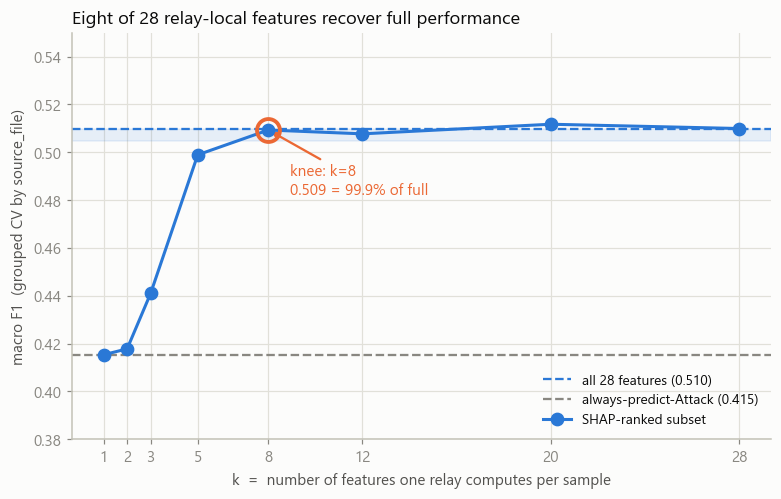

In [28]:
#Feature-reduction curve plot
CONST_F1 = 0.4153

fig, ax = plt.subplots(figsize=(8.2, 4.8))
ax.axhspan(full * (1 - TOL), full, color=C["s1"], alpha=0.10, zorder=1)
ax.axhline(full, ls="--", lw=1.5, color=C["s1"], zorder=2,
           label=f"all 28 features ({full:.3f})")
ax.axhline(CONST_F1, ls="--", lw=1.5, color=C["muted"], zorder=2,
           label=f"always-predict-Attack ({CONST_F1:.3f})")
ax.plot(curve.k, curve.macro_f1, "-o", lw=2, ms=8, color=C["s1"], zorder=4,
        label="SHAP-ranked subset")
ax.plot([knee], [knee_f1], "o", ms=15, mfc="none", mec=C["s2"], mew=2.5, zorder=5)
ax.annotate(f"knee: k={knee}\n{knee_f1:.3f} = {knee_f1/full:.1%} of full",
            xy=(knee, knee_f1), xytext=(14, -42), textcoords="offset points",
            fontsize=10, color=C["s2"],
            arrowprops=dict(arrowstyle="->", color=C["s2"], lw=1.5))
ax.set_xlabel("k  =  number of features one relay computes per sample")
ax.set_ylabel("macro F1  (grouped CV by source_file)")
ax.set_title("Eight of 28 relay-local features recover full performance")
ax.set_xticks(curve.k); ax.set_ylim(0.38, 0.55)
ax.legend(loc="lower right", fontsize=9)
savefig(fig, "fig6_reduction_curve")

# **Reduction Curve Interpretation**
Eight of the 28 relay-local features recover essentially all of the performance. With the knee of the curve sitting at 8, the SHAP analysis ranks that set of features as performing 0.094 better than the baseline macro-F1 of 0.415 from always predicting Attack. The curve also shows evidence that the pipeline itself is not leaking, as the first point, k=1, reports a macro-F1 of 0.4153, which means that no single feature carries anything on its own. Although the feature that was believed to be the most distinguishing among the set, `PA:Z`, was not in the top 8 selected by SHAP (it was ranked 9th, so it barely did not make the cut), `PA:ZH`, the impedance angle, did make the top 8 features. This suggests that rather than the magnitude of the impedance being the most determining factor, the angle itself was more telling of fault character (resistive vs. reactive), insofar as a single relay's local view. However, another important aspect to note is that although the feature set can be reduced to 8 without sacrificing performance, the detection itself is still far from perfect. Reducing from 28 to 8 features costs nothing performance-wise, but both are weak under the honest, non-leaky methodology of this project. 1% relative was used, meaning that features stop being removed after the model drops 1% from its peak performance in terms of macro-F1. This decision was made to maintain the integrity of the feature set and results. 

## **12. Leave-one-relay-out generalization**

No real utility has relays with their own labelled attack data. Using the Leave-One-Relay-Out approach allows us to see if the detector is able to generalize across relays it hasn't seen before.

In [29]:
def leave_one_relay_out(model, frame, feats, z_cols=Z_LONG) -> pd.DataFrame:
    #Train on three relays, test on the held-out fourth; repeat all four ways
    rows = []
    for r in RELAYS:
        tr = frame["relay_id"] != r
        te = ~tr
        X_tr, X_te = frame.loc[tr, feats], frame.loc[te, feats]
        y_tr = (frame.loc[tr, "marker"] == "Attack").astype(int)
        y_te = (frame.loc[te, "marker"] == "Attack").astype(int)

        z   = [c for c in z_cols if c in feats]       # same filter as §11
        pol = fit_inf_policy(X_tr, z)                 # training relays only
        fitted = clone(model).fit(apply_inf_policy(X_tr, pol, z), y_tr)
        pred   = fitted.predict(apply_inf_policy(X_te, pol, z))
        rows.append({"held_out_relay": f"R{r}", **_metrics(y_te, pred)})
    return pd.DataFrame(rows).set_index("held_out_relay")


MINIMAL = list(ranking[:knee])
print(f"minimal set (k={knee}): {MINIMAL}\n")

loro_full = leave_one_relay_out(MODELS["XGBoost"], long_df, GENERIC_PMU_28)
loro_min  = leave_one_relay_out(MODELS["XGBoost"], long_df, MINIMAL)

comp = pd.DataFrame({"full 28": loro_full["macro_f1"], f"minimal {knee}": loro_min["macro_f1"]})
comp.loc["mean"] = comp.mean()
display(comp.round(4))

print(f"\nin-distribution grouped reference: full {full:.4f} | minimal {knee_f1:.4f}")
print(f"transfer gap  full={full - loro_full.macro_f1.mean():+.4f}  "
      f"minimal={knee_f1 - loro_min.macro_f1.mean():+.4f}")

minimal set (k=8): ['PM2:V', 'PM1:V', 'PM5:I', 'F', 'PA3:VH', 'PM4:I', 'PA2:VH', 'PA:ZH']



,full 28,minimal 8
held_out_relay,,
R1,0.5599,0.5561
R2,0.5864,0.5846
R3,0.5367,0.5326
R4,0.5435,0.5240
mean,0.5566,0.5493



in-distribution grouped reference: full 0.5099 | minimal 0.5093
transfer gap  full=-0.0467  minimal=-0.0401


WindowsPath('figures/fig7_leave_one_relay_out.png')

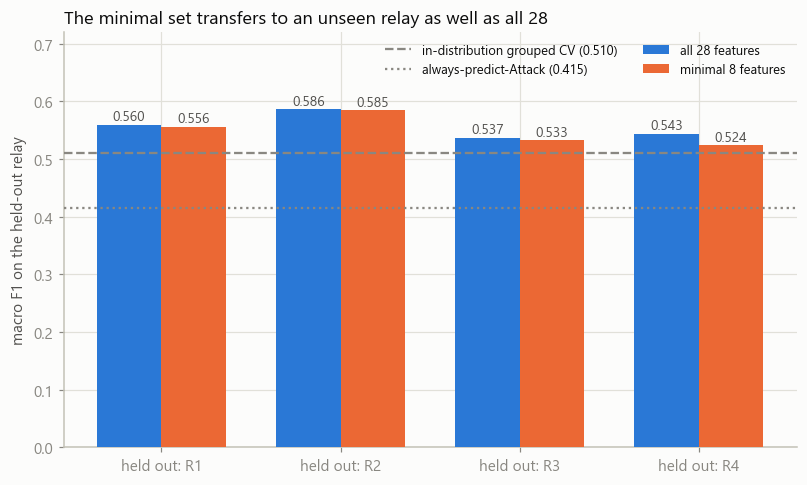

In [30]:
#Leave-one-relay-out comparison Visualization
fig, ax = plt.subplots(figsize=(8.6, 4.9))
x, w = np.arange(len(RELAYS)), 0.36

for k, (series, col, lab) in enumerate([
        (loro_full["macro_f1"], C["s1"], "all 28 features"),
        (loro_min["macro_f1"],  C["s2"], f"minimal {knee} features")]):
    bars = ax.bar(x + (k - 0.5) * w, series.values, w, color=col, label=lab, zorder=3)
    for b, v in zip(bars, series.values):
        ax.text(b.get_x() + b.get_width()/2, v + 0.008, f"{v:.3f}",
                ha="center", fontsize=9, color=C["ink2"])

ax.axhline(full, ls="--", lw=1.5, color=C["muted"], zorder=4,
           label=f"in-distribution grouped CV ({full:.3f})")
ax.axhline(CONST_F1, ls=":", lw=1.5, color=C["muted"], zorder=4,
           label=f"always-predict-Attack ({CONST_F1:.3f})")

ax.set_xticks(x, [f"held out: {r}" for r in loro_full.index])
ax.set_ylabel("macro F1 on the held-out relay")
ax.set_ylim(0, 0.72)                      
ax.set_title("The minimal set transfers to an unseen relay as well as all 28")
ax.legend(loc="upper right", fontsize=8.5, ncol=2)
savefig(fig, "fig7_leave_one_relay_out")

# **Leave-One-Relay-Out Comparison Interpretation**

The data above shows that the minimal set transfers as well as the full set of 28 features. On R1, R2, and R3, the full set of 28 performed only 0.004, 0.001, and 0.004 higher in macro-F1 score than the 8-feature set. The only relay with a noticeably larger gap compared to the others was R4, where the 28 feature set performed better by 0.018. This gap is small enough that a relay-local reduced-feature detector is defensible. However, because the long format gives every snapshot one row per relay, the same physical event and timestamp appears in both the training and the test set under leave-one-relay-out as a different relay's view, but the same instant with the same label. Therefore, LORO measures **feature-space transfer across relays**, not temporal generalization. The grouped-CV protocol from section 7 is what covers the temporal axis. 

## **13. Synthesis, limitations, and future work**

**13.1: Answering the Research Question**

**Minimal Feature Set**: 8 of 28 relay-generic features reach macro-F1 of 0.5093 against 0.5099 for all 28, within 99.9%, under grouped cross-validation. The features that were selected for the final 8 were: `PM2:V`, `PM1:V`, `PM5:I`, `F`, `PA3:VH`, `PM4:I`, `PA2:VH`, and `PA:ZH`. Interestingly, this set contains **no symmetrical components**, that is to say they come from only raw three-phase quantities, frequency, and the impedance angle. Further, the minimal set contains `PA:ZH` (impedance angle) but **not** `PA:Z`, even though Section 3 identifies impedance magnitude as the theoretically central quantity and prior work ranks it top. 

**Cross-relay Generalization**: Leave-One-Relay-Out (LORO) mean macro-F1 is 0.5566 (full 28) vs 0.5493 (minimal set), representing a gap of 0.0073. The reduced set transfers to an unseen relay essentially as well as the complete one. Reducing the feature set from 28 to 8 costs nothing in either in-distribution performance or cross-relay transfer. 

**13.2: Methodological Findings**

Rows are 99.92% autocorrelated in contiguous blocks, meaning a random split places near-duplicate neighbors in both the training and test set. Because of this, results like Random Forest's 0.8994 macro-F1 under the random split are produced, but 0.6004 macro-F1 is produced when whole recording sessions are held out. The idea of data memorization is also demonstrated in Logistic Regression's gap being 0.002 between the grouped vs. random split protocols, while XGBoost weighted model and Random Forest, models that rely on individual rows, jump to gaps of 0.157 and 0.299 in macro-F1, respectively. A linear model like LR can't memorize those individual rows, so it is less prone to the same leaky protocol that Random Forest and XGBoost memorize under. This claim is also resistant to different grouping methods, with the following results per grouping: source_file 0.6064, block 0.5896, event 0.6132 - a range of 0.0236. 

**Methodology Decision Summary Table**
| Decision | Justification | Evidence |
| ---------| --------------| ---------|
|Infinities -> flag + cap, not dropped|10,906 inf mark breaker-open states; current exactly 0, voltage nominal|Section 4, Fig. 3|
|12 log columns excluded|logs-only macro-F1 0.4501 vs. 0.4168 constant (12K sample); snort fires only 4-7 times in 78K rows|Section 6|
|4 status words excluded|Bitfield isn't a quantity; allows the model to cheat by seeing the state when it's supposed to be predicting; `R4:S` is float64 with negatives|Section 6|
|Grouped CV by `source_file`|99.92% adjacent-row label agreement makes random splits leak|Sections 4 & 7|
|Relay-generic 28-feature space|The research question's second half requires features that transfer across relays|Section 8|
|SHAP as the primary feature ranking|Permutation splits credit across correlated phase voltages|Section 10|

**13.3: Limitations** 
- LORO shares events between train and test. Every snapshot appears as four relay-rows, so the held-out relay's timestamps were seen through the other three. This is proven through the negative transfer gap (-0.0467 in the full set, -0.0401 in the minimal set). LORO scored higher than in-distribution in grouped CV, which is only possible because of its easier partition. 
- Labels are system level, inherited by all four relay-rows, so a remote relay is labeled "Attack" for a disturbance it may barely see or be a part of. 
- **Absolute Performance is low.** Everything honest, relating to this project's methods for grouping protocol rather than the leaky random split, sits between 0.51 and 0.61 against a floor of 0.4168 (the macro-F1 score produced from guessing "Attack" every time on the full dataset). In the end, this implies that a single, isolated relay observing only its local data does NOT have enough context to cleanly or fully reliably determine natural faults from cyber attacks. Instead, these findings from this project suggest that grids must use multi-relay consensus rather than relying on decentralized edge-intelligence.
- No hyperparameter tuning. This decision was made deliberately, as tuning on a leaky protocol optimizes for the leak, and doing it properly needs nested CV. 
- **The inf cap quantile (0.999) was chosen rather than tuned**. 
- Single testbed, the 3-bus/2-line topology from MSU and ORNL.
- Importance rankings come from one fold.

**13.4: Future Work**
1. Hold out relay *and* time blocks simultaneously to strictly test LORO
2. Check whether the 8-feature set survives on a different topology
3. Investigate why the **impedance angle** outranks magnitude by SHAP analysis. 
